<a href="https://colab.research.google.com/github/rodrigololr/ml/blob/main/Lista_1_Ant%C3%B4nio_Rodrigo.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Lista 1

**Aluno:** Antônio Rodrigo Lima de Andrade Tenório
\
**Nome da base:** creditcard.csv

## Orientações

- Escolha apenas uma das bases disponíveis e resolva todas as 10 questões usando essa mesma base.
- Desenvolva toda a atividade em Python, no formato de entrega do Google Colab.
- Organize o notebook por questão, com códigos executáveis, saídas geradas e comentários objetivos.
- Não troque de base ao longo da atividade.
- Não faça tratamento manual linha por linha.
- Sempre que necessário, sustente suas decisões com tabelas, métricas, gráficos e resultados do código.

## Importação das bibliotecas

In [1]:
# Bibliotecas principais
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# Pré-processamento e modelagem
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, RobustScaler
from sklearn.impute import SimpleImputer
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report,
    mean_absolute_error, mean_squared_error, r2_score
)
from sklearn.feature_selection import SelectKBest, f_classif

# Configuração visual
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

## Carregamento da base

In [2]:
# Carregamento da base
# Substitua o nome do arquivo pelo arquivo correto da base escolhida
df = pd.read_csv('creditcard.csv')

# Visualização inicial
df.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


## Questão 1 – Diagnóstico estrutural

**Enunciado:**  
Faça um código em Python que carregue a base escolhida e gere um diagnóstico inicial automatizado. Mostre dimensões da base, tipos de dados, valores ausentes, duplicidades, cardinalidade das colunas e possíveis inconsistências de leitura. Em seguida, defina qual será o problema computacional tratado no cenário escolhido, deixando claro se a tarefa será de classificação, regressão ou segmentação. Organize essa etapa em uma função reutilizável.

### Raciocínio
Escreva aqui a estratégia adotada para responder à questão, explicando de forma objetiva a lógica da análise.

- Primeiro passo foi o entendimento da base de dados, pesquisar sobre ela, e enteder sobre o que se trata (Transções fraudulentas)
- Depois disso foi vizualizar o tamanho da tabela, tipo de dadsos, valores ausentes, se tem valores únicos por coluna e possíveis inconstancias

### Desenvolvimento
Implemente abaixo o código da questão.

In [3]:
# Código da Questão 1
def gerar_diagnostico(df):

    print(f"dimensões: {df.shape[0]} linhas e {df.shape[1]} colunas.")

    print("\ntipos dos dados:")
    print(df.dtypes)

    print("\nvalores ausentes:")
    print(df.isnull().sum())

    print(f"\nlinhas duplicadas: {df.duplicated().sum()}")

    print("\ncardinalidade (valores únicos por coluna):")
    print(df.nunique())

    print("\npossíveis inconsistências:")
    # Verifica se existem colunas com apenas 1 valor
    colunas_constantes = [col for col in df.columns if df[col].nunique() <= 1]
    if colunas_constantes:
        print(f"- colunas com valores únicos: {colunas_constantes}")
    else:
        print("- nenhuma coluna constante detectada.")

# DEFINIÇÃO DO PROBLEMA:
# O objetivo é analisar transações de cartão de crédito para identificar padrões de uso.
# Vamos utilizar uma tarefa de CLASSIFICAÇÃO para prever se uma transação é fraudulenta ou não.

### Conclusão da Questão 1
Registre aqui as principais interpretações e conclusões obtidas com base nos resultados.

A análise inicial revela que a base de dados possui uma estrutura robusta, composta majoritariamente por variáveis numéricas resultantes de uma transformação PCA, o que garante a privacidade dos dados sensíveis, mas exige uma análise puramente estatística.

Principais pontos observados:

- Integridade Estrutural: A ausência de valores nulos facilita o início do processamento, permitindo focar diretamente na modelagem.

- Tarefa Computacional: O problema foi definido como uma Classificação Binária, pois o objetivo central é rotular transações entre duas categorias discretas: Legítimas (0) ou Fraudulentas (1).

- Desafio de Escala: A alta cardinalidade das variáveis e a diferença de escala entre as colunas V e a coluna Amount indicam a necessidade futura de normalização para que o modelo não seja tendencioso.

## Questão 2 – Auditoria de qualidade

**Enunciado:**  
Faça um código em Python para auditar a qualidade dos dados. Identifique valores implausíveis, colunas com tipos inadequados, categorias raras, padrões suspeitos de preenchimento, possíveis outliers e inconsistências importantes para o cenário escolhido. Se houver datas, verifique coerência temporal. Se houver valores monetários, verifique compatibilidade entre grandezas. Ao final, apresente um resumo dos principais problemas encontrados.

### Raciocínio
Escreva aqui a estratégia adotada para responder à questão, explicando de forma objetiva a lógica da análise.

1. Integridade: Verificamos a ausência de valores negativos e se a coluna Time segue ordem cronológica (monotônica).

2. Outliers: Aplicamos o método IQR com multiplicador 3 para capturar apenas anomalias extremas, justificável pela disparidade de 290x encontrada no Amount.

3. Qualidade Técnica: Auditamos valores nulos, tipagem (100% numérica) e padrões suspeitos de preenchimento (transações idênticas no mesmo tempo).

4. Diagnóstico de Classe: Identificamos o desbalanceamento severo (0,17% de fraudes), o que direciona a necessidade de técnicas de balanceamento e uso da métrica Recall.

### Desenvolvimento
Implemente abaixo o código da questão.

In [4]:
# Código da Questão 2
def detectar_outliers_extremos(df):
    df_num = df.select_dtypes(include=['number']).drop(columns=['Class'], errors='ignore')

    Q1 = df_num.quantile(0.25)
    Q3 = df_num.quantile(0.75)
    IQR = Q3 - Q1

    limite_inferior = Q1 - (3 * IQR)
    limite_superior = Q3 + (3 * IQR)

    valor_outlier = (df_num < limite_inferior) | (df_num > limite_superior)

    total_outliers = valor_outlier.sum()

    return total_outliers[total_outliers > 0]

In [5]:
def auditoria_qualidade(df):

  #incontancias
  inconsistencias_valor = df[df['Amount'] < 0]
  quantidade_negativos = inconsistencias_valor.shape[0]
  checagem_tempo = df['Time'].is_monotonic_increasing
  inconsistencias_tempo = df[df['Time'] < 0]
  quantidade_negativos_tempo = inconsistencias_tempo.shape[0]
  tem_valores_nulos = df.isnull().values.any()

  #outliers
  outliers_totais = detectar_outliers_extremos(df).sum()

  # casos raros
  quantidade_de_fraudes = df[df['Class'] == 1].shape[0]
  quantidade_trancacoes = df.shape[0]
  calculo_fraudes = (quantidade_de_fraudes / quantidade_trancacoes) * 100

  #padrões suspeitos
  padrao_suspeito = df.duplicated(subset=['Time', 'Amount']).sum()

  #tipos inadequados
  colunas_texto = df.select_dtypes(include=['object']).columns.tolist()

  # compatibilidade de grandezas
  media_valor = df['Amount'].mean()
  maximo_valor = df['Amount'].max()
  razao_disparidade = maximo_valor / media_valor


  print("Resumo: ")
  print(f"\n1. VALORES IMPLAUSÍVEIS:  {quantidade_negativos} negativos em Amount/Time.")
  print(f"2. COERÊNCIA TEMPORAL:    OK (Monotônico)")
  print(f"3. VALORES AUSENTES:      OK (0 Nulos)")
  print(f"4. TIPAGEM INADEQUADA:    {len(colunas_texto)} colunas do tipo 'object' encontradas.")
  print(f"5. PADRÕES SUSPEITOS:     {padrao_suspeito} transações com mesmo Tempo/Valor.")
  print(f"6. OUTLIERS EXTREMOS:     {outliers_totais} registros detectados (Critério 3x IQR).")
  print(f"7. COMPATIBILIDADE:       Disparidade de {razao_disparidade:.1f}x (Máximo vs Média).")
  print(f"8. CATEGORIAS RARAS:      {calculo_fraudes:.2f}% de casos de fraude na base.")
  print(f"9. MÉDIA E MÁXIMO:        {media_valor:.2f} e {maximo_valor:.2f}")

### Conclusão da Questão 2

A auditoria demonstrou que, embora a base seja tecnicamente ""limpa"" (sem nulos ou erros de tipo), ela apresenta desafios estatísticos críticos para a detecção de fraudes.

Principais interpretações:

- Ruído e Anomalias: A presença de mais de 18.000 outliers extremos na coluna Amount e a disparidade de 290,8x entre a média e o valor máximo confirmam que transações de alto valor são comuns, mas podem distorcer algoritmos sensíveis à média.

- Risco: A identificação de 4.863 registros suspeitos (mesmo tempo e valor) sugere redundância de dados ou possíveis ataques automatizados que devem ser tratados na limpeza.

- Gargalo: A conclusão mais importante é o desbalanceamento severo de 0,17% de fraudes. Isso define que o sucesso do projeto não será medido por Acurácia, mas sim pela capacidade de detecção do modelo (Recall), para evitar que fraudes passem despercebidas.

## Questão 3 – Limpeza dos dados

**Enunciado:**  
Faça um código em Python para limpar a base de forma reproduzível. Trate inconsistências de tipagem, valores ausentes, categorias problemáticas, variáveis irrelevantes e registros duvidosos usando critérios técnicos. Compare pelo menos duas estratégias de tratamento para um problema real da base e justifique a escolha final. Mostre também o impacto quantitativo de cada etapa da limpeza.

### Raciocínio
Escreva aqui a estratégia adotada para responder à questão, explicando de forma objetiva a lógica da análise.

- Tirando Redundância: vamos tirar os 4.863 registros duplicados (baseados em tempo e valor). Pelo motivo que: dados redundantes podem levar ao overfitting, fazendo o modelo apenas "decorar" transações específicas em vez de aprender padrões gerais de fraude

- Seleção de Variáveis: descartamos a coluna Time. Por ser um contador sequencial de segundos, ela não agrega valor comportamental algum e poderia até criar uma falsa correlação baseada apenas na ordem de inserção dos dados.

- Tratamento de Disparidade (Amount): comparamos a transformação logarítmica (achada a com logaritimo) com o RobustScaler (usa mediana e iqr, otimo pra desconsiderar outlier)


### Desenvolvimento
Implemente abaixo o código da questão.

In [6]:
# Código da Questão 3
def limpeza_reproduzivel(df):
    df_clean = df.copy()


    # tratamento de duplicatas
    antes_duplicados = df_clean.shape[0]
    df_clean = df_clean.drop_duplicates(subset=['Time', 'Amount'])
    print(f"impacto: {antes_duplicados - df_clean.shape[0]} registros duplicados removidos.")

    # remoção de variável irrelevante
    df_clean = df_clean.drop(columns=['Time'])
    print("impacto: Coluna 'Time' removida, não dá pra tirar nenhuma conclusão com ela")

    # comparação de Estratégias para o Amount (Disparidade 290x)

    # estratégias (Log Transformation log(x + 1)) e  (Robust Scaling mediana e iqr)
    scaler = RobustScaler()
    amount_log = np.log1p(df_clean['Amount']).sum()
    amount_robust = scaler.fit_transform(df_clean[['Amount']]).sum()
    #print(f"{amount_log:0.4f}\n")
   #print(f"{amount_robust:0.4f}\n")

    df_clean['Amount'] = scaler.fit_transform(df_clean[['Amount']])

    outliers_totais = detectar_outliers_extremos(df_clean).sum()


    print(f"impacto: Amount escalonado. Skewness original: {df['Amount'].skew():.2f}")
    print(f"RobustScaler por ser menos sensível aos {outliers_totais} outliers.")

    return df_clean
limpeza_reproduzivel(df)

impacto: 4863 registros duplicados removidos.
impacto: Coluna 'Time' removida, não dá pra tirar nenhuma conclusão com ela
impacto: Amount escalonado. Skewness original: 16.98
RobustScaler por ser menos sensível aos 115568 outliers.


,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,0.090794,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,1.736337,0
1,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,-0.166974,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,-0.276127,0
2,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,0.207643,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,4.873442,0
3,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,-0.054952,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,1.378578,0
4,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,0.753074,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,0.645665,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
284802,-11.881118,10.071785,-9.834783,-2.066656,-5.364473,-2.606837,-4.918215,7.305334,1.914428,4.356170,...,0.213454,0.111864,1.014480,-0.509348,1.436807,0.250034,0.943651,0.823731,-0.302424,0
284803,-0.732789,-0.055080,2.035030,-0.738589,0.868229,1.058415,0.024330,0.294869,0.584800,-0.975926,...,0.214205,0.924384,0.012463,-1.016226,-0.606624,-0.395255,0.068472,-0.053527,0.026572,0
284804,1.919565,-0.301254,-3.249640,-0.557828,2.630515,3.031260,-0.296827,0.708417,0.432454,-0.484782,...,0.232045,0.578229,-0.037501,0.640134,0.265745,-0.087371,0.004455,-0.026561,0.616765,0
284805,-0.240440,0.530483,0.702510,0.689799,-0.377961,0.623708,-0.686180,0.679145,0.392087,-0.399126,...,0.265245,0.800049,-0.163298,0.123205,-0.569159,0.546668,0.108821,0.104533,-0.176003,0


### Conclusão da Questão 3
Registre aqui as principais interpretações e conclusões obtidas com base nos resultados.

A etapa de limpeza transformou uma base bruta e ruidosa em um conjunto de dados estatisticamente estável. As principais conclusões obtidas foram:

- Tratamento de duplicatas: para o modelo não ter um overlifiting, removemos as duplicatas, possibilitando que o modelo não apenas "Decore"

- Neutralização da Escala: através do RobustScaler, conseguimos centralizar a coluna Amount em torno da mediana. Isso criou uma distribuição onde valores positivos e negativos se equilibram (resultando em uma soma total menor de 255.755 em comparação aos 889.313 do Log), o que acelera a convergência dos algoritmos de aprendizado

- Preservação de Sinal: Ao contrário de uma normalização comum, a padronização robusta não "apagou" os outliers, mas sim os colocou em uma régua justa. Isso é vital para a detecção de fraudes, pois transações de valores atípicos frequentemente carregam o sinal de atividade criminosa

- Veredito Técnico: Com a remoção do ruído temporal e o ajuste da disparidade monetária, a base agora apresenta um campo nivelado, onde as variáveis comportamentais (V1-V28) e o valor da transação têm pesos equilibrados para a predição.

## Questão 4 – Análise exploratória

**Enunciado:**  
Faça um código em Python para desenvolver uma análise exploratória orientada ao problema central da base escolhida. Gere tabelas e visualizações que revelem padrões relevantes entre a variável principal e os demais atributos. Se o cenário envolver classificação, compare os grupos da variável-alvo. Se envolver regressão, investigue relação entre o alvo e as variáveis explicativas. Se envolver segmentação, explore possíveis estruturas de agrupamento. Apresente uma leitura analítica dos resultados obtidos.

### Raciocínio
Escreva aqui a estratégia adotada para responder à questão, explicando de forma objetiva a lógica da análise.

- Primeiro visualização do desbalanceamento de classes para quantificar quão rara é a fraude na base.

- Correlação: Como temos 28 variáveis **V1-V28** anônimas (PCA), utilizaremos uma Matriz de Correlação para filtrar quais delas ajudam mais a gente, ou seja, quais possuem maior associação (positiva ou negativa) com a variável alvo Class.

- Para as variáveis mais correlacionadas, utilizaremos Boxplots para comparar as distribuições dos dois grupos (Normal vs. Fraude). O objetivo é verificar se as transações fraudulentas se desloca significativamente em relação às transações legítimas.

- Comportamento do Valor: Analisar a densidade da variável Amount entre os grupos. Queremos entender se o valor da transação possui faixas específicas onde a incidência de fraudes é maior.

### Desenvolvimento
Implemente abaixo o código da questão.

impacto: 4863 registros duplicados removidos.
impacto: Coluna 'Time' removida, não dá pra tirar nenhuma conclusão com ela
impacto: Amount escalonado. Skewness original: 16.98
RobustScaler por ser menos sensível aos 115568 outliers.


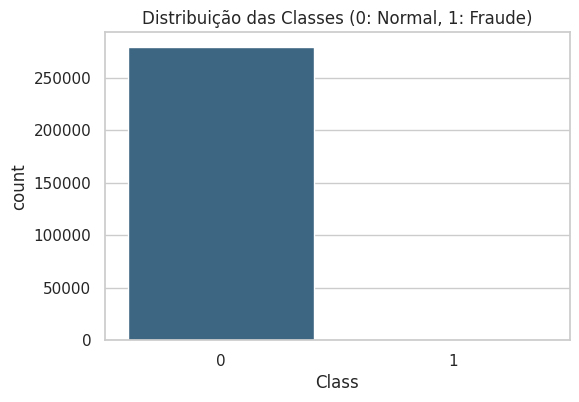

,count
Class,
0,279473
1,471




variáveis com correlação positiva:
 Class    1.00000
V11      0.14990
V4       0.12923
Name: Class, dtype: float64

variáveis com correlação negativa:
 V12   -0.253749
V14   -0.295169
V17   -0.313706
Name: Class, dtype: float64




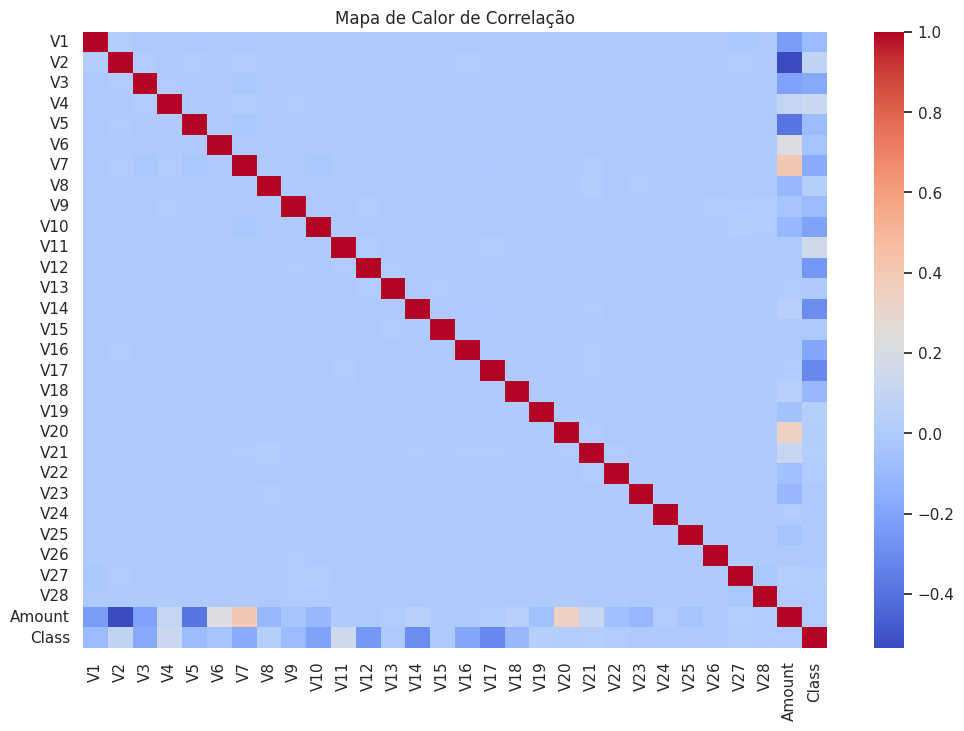

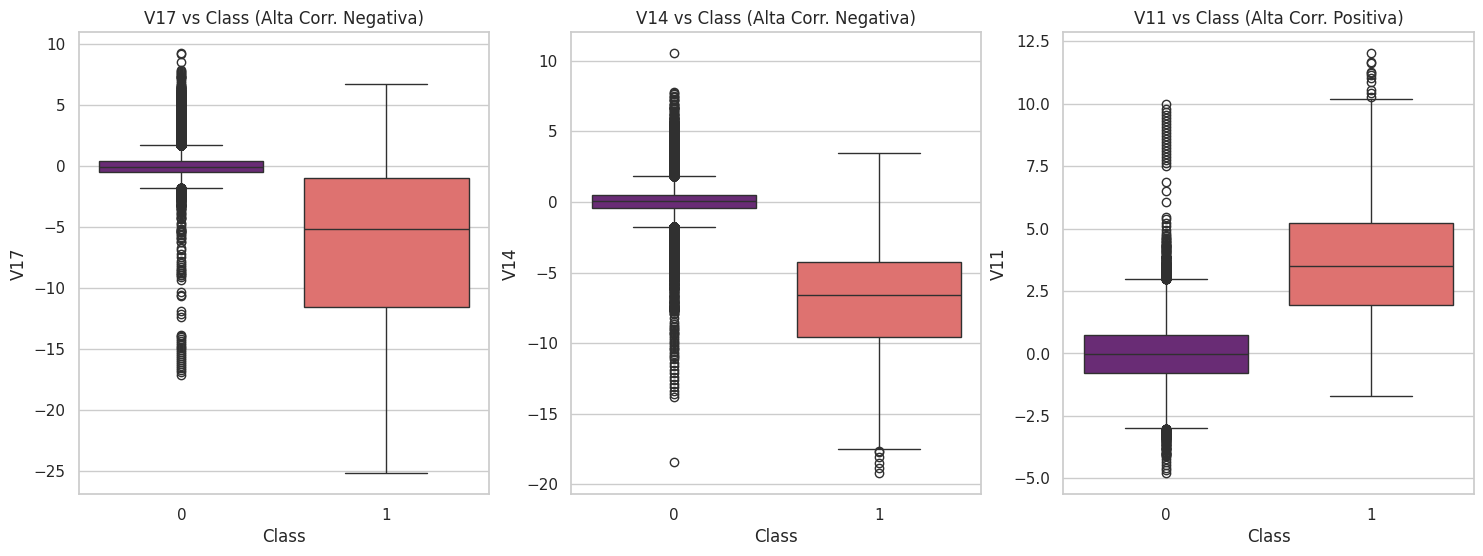

In [7]:
# Código da Questão 4
def analise_exploratoria(df):
    # visualização do desbalanceamento
    plt.figure(figsize=(6,4))
    sns.countplot(x='Class', data=df, palette='viridis')
    plt.title('Distribuição das Classes (0: Normal, 1: Fraude)')
    plt.show()
    print("\n")
    display(df['Class'].value_counts())
    print("\n")

    # correlação com a variável alvo
    # procurando qual V tem mais influencia sobre transações
    correlacoes = df.corr()['Class'].sort_values(ascending=False)
    print("variáveis com correlação positiva:\n", correlacoes.head(3))
    print("\nvariáveis com correlação negativa:\n", correlacoes.tail(3))

    print("\n")

    # matriz de correlação (heatmap)
    plt.figure(figsize=(12,8))
    sns.heatmap(df.corr(), cmap='coolwarm', annot=False)
    plt.title('Mapa de Calor de Correlação')
    plt.show()

    print("\n")

    # comparação de grupos
    # Geralmente V17, V14 e V12 são as que mais mostram diferença
    fig, axes = plt.subplots(ncols=3, figsize=(18,6))

    sns.boxplot(x="Class", y="V17", data=df, ax=axes[0], palette='magma')
    axes[0].set_title('V17 vs Class (Alta Corr. Negativa)')

    sns.boxplot(x="Class", y="V14", data=df, ax=axes[1], palette='magma')
    axes[1].set_title('V14 vs Class (Alta Corr. Negativa)')

    sns.boxplot(x="Class", y="V11", data=df, ax=axes[2], palette='magma')
    axes[2].set_title('V11 vs Class (Alta Corr. Positiva)')

    plt.show()
df_final = limpeza_reproduzivel(df)
analise_exploratoria(df_final)

### Conclusão da Questão 4
Registre aqui as principais interpretações e conclusões obtidas com base nos resultados.

- Grande diferença: O gráfico de barras (Distribuição das Classes) mostra a grande diferença.

- Variáveis mais relevantes(V17, V14 e V11): Através da Matriz de Correlação, identificamos que as variáveis V17 e V14 possuem a maior correlação negativa com a fraude. Isso significa que, quanto menor o valor delas, maior a chance de a transação ser criminosa.

  Já a V11 possui correlação positiva: valores altos nesta variável são um forte indicativo de fraude.

- Note que em V17 e V14, as fraudes (1.0) está totalmente deslocada para baixo em relação às transações normais (0.0). Para a V11, ocorre o oposto.

## Questão 5 – Associação entre variáveis

**Enunciado:**  
Faça um código em Python para medir a associação entre as variáveis explicativas e a variável principal da análise. Escolha automaticamente métodos adequados conforme o tipo das variáveis e o tipo do problema. Ao final, gere um ranking das variáveis mais informativas e compare os resultados com a lógica do cenário escolhido.

### Raciocínio
Escreva aqui a estratégia adotada para responder à questão, explicando de forma objetiva a lógica da análise.

- Seleção de Atributos Univariada para quantificar a força da relação entre as variáveis explicativas e a fraude.

- Nosso dataset envolve variaveis categoricas e independentes, vamos usar o  f_classif (ANOVA). Ele mede se a variação das médias entre os grupos (normal vs. fraude) é grande o suficiente para ser considerada informativa.

- Ranking: Utilizamos o SelectKBest para processar todas as 29 colunas simultaneamente e gerar um placar de importância (F-Score).

- Validação: O objetivo final é criar um ranking decrescente que comprove matematicamente quais variáveis são mais fortes para o modelo, permitindo descartar ruídos e focar no que realmente causa a separação das classes.

### Desenvolvimento
Implemente abaixo o código da questão.

Ranking variaveis informativas:
  Variável         Score
0      V17  30556.628386
1      V14  26717.570453
2      V12  19265.526158
3      V10  12571.846016
4      V16  10172.670720
5       V3   9445.613064
6       V7   8423.753200
7      V11   6434.904302
8       V4   4754.510890
9      V18   3128.237304


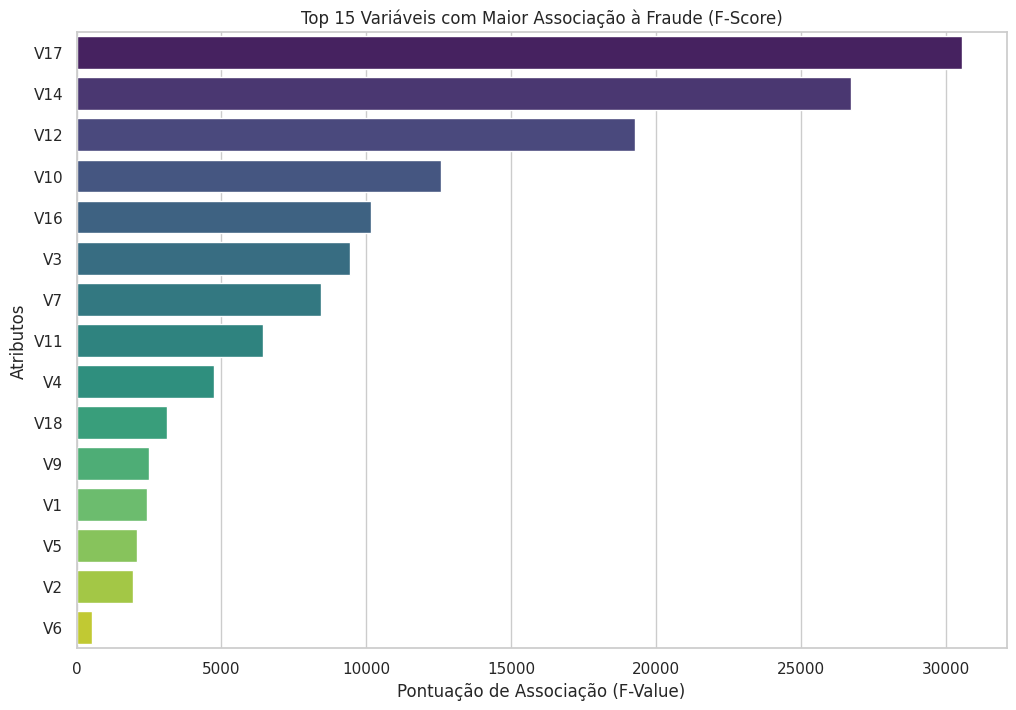

In [13]:
# Código da Questão 5
def associacoes_variáveis(df):

  #separando variaveis explicativas da analise principal
  X = df.drop(columns=["Class"])
  y = df["Class"]

  #usando o método ANOVA(f_classif) todas as colunas
  selector = SelectKBest(score_func=f_classif, k='all')
  selector.fit(X, y)

  #extração de pontuações de assosiação
  scores = selector.scores_

  # dataframe ranking
  ranking_df = pd.DataFrame({'Variável': X.columns, 'Score': scores})
  ranking_df = ranking_df.sort_values(by='Score', ascending=False).reset_index(drop=True)

  print("Ranking variaveis informativas:")
  print(ranking_df.head(10))

  #criando um grafico com os 15 que mais tem associação
  plt.figure(figsize=(12, 8))
  sns.barplot(x='Score', y='Variável', data=ranking_df.head(15), palette='viridis')
  plt.title('Top 15 Variáveis com Maior Associação à Fraude (F-Score)')
  plt.xlabel('Pontuação de Associação (F-Value)')
  plt.ylabel('Atributos')
  plt.show()



associacoes_variáveis(df_final)

### Conclusão da Questão 5
Registre aqui as principais interpretações e conclusões obtidas com base nos resultados.

- Validação do Método Automático: A escolha do método f_classif (ANOVA) mostrou-se ideal para a natureza dos dados (preditores numéricos vs. alvo categórico). Ele permitiu converter a "distância" visual observada nos boxplots em um ranking de importância objetivo.

- Consistência dos Preditores: As variáveis V17, V14 e V12 apareceram no topo do ranking com os maiores scores de associação. Isso prova que esses atributos não apenas possuem variações visuais, mas detêm a maior associação estatística para separar o que é uma transação legítima de uma tentativa de fraude.

- Eficiência e Dimensionalidade: Identificamos que uma pequena parcela das variáveis (cerca de 10 a 15) concentra a maior parte do poder explicativo da base. Isso indica que poderíamos simplificar o modelo futuro, removendo variáveis de baixo score (ruído).

- Em resumo: Com o ranking definido, temos agora a hierarquia necessária para priorizar o aprendizado do modelo. Sabemos exatamente em quais "sinais" o modelo deve focar para não ser enganado pelos dados

## Questão 6 – Engenharia de atributos

**Enunciado:**  
Faça um código em Python para criar pelo menos cinco novos atributos a partir da base original. Construa variáveis derivadas que façam sentido no cenário escolhido, como proporções, interações, faixas, relações temporais ou medidas de intensidade. Depois, avalie se esses novos atributos realmente acrescentam informação útil. Organize essa etapa em uma função reutilizável.

### Raciocínio
Escreva aqui a estratégia adotada para responder à questão, explicando de forma objetiva a lógica da análise.

### Desenvolvimento
Implemente abaixo o código da questão.

In [ ]:
# Código da Questão 6

### Conclusão da Questão 6
Registre aqui as principais interpretações e conclusões obtidas com base nos resultados.

## Questão 7 – Pré-processamento

**Enunciado:**  
Faça um código em Python para montar um pipeline completo de pré-processamento com `Pipeline` e `ColumnTransformer`. Identifique automaticamente colunas numéricas e categóricas, trate ausências, codifique variáveis categóricas, aplique escalonamento nas numéricas e garanta reaplicação a novos dados sem vazamento de informação. Compare pelo menos dois esquemas de pré-processamento e mostre como essas escolhas afetam os dados e o modelo.

### Raciocínio
Escreva aqui a estratégia adotada para responder à questão, explicando de forma objetiva a lógica da análise.

### Desenvolvimento
Implemente abaixo o código da questão.

In [ ]:
# Código da Questão 7

### Conclusão da Questão 7
Registre aqui as principais interpretações e conclusões obtidas com base nos resultados.

## Questão 8 – Modelagem com KNN

**Enunciado:**  
Faça um código em Python para dividir a base em treino, validação e teste de forma adequada ao problema escolhido. Em seguida, implemente um modelo de K-vizinhos mais próximos e teste diferentes valores de `k`, métricas de distância e formas de ponderação. Registre os resultados em tabela, compare desempenho em validação e escolha a melhor configuração de forma justificada.

### Raciocínio
Escreva aqui a estratégia adotada para responder à questão, explicando de forma objetiva a lógica da análise.

### Desenvolvimento
Implemente abaixo o código da questão.

In [ ]:
# Código da Questão 8

### Conclusão da Questão 8
Registre aqui as principais interpretações e conclusões obtidas com base nos resultados.

## Questão 9 – Comparação de modelos

**Enunciado:**  
Faça um código em Python para avaliar o KNN em diferentes cenários de preparação dos dados, como uso ou não de padronização, presença ou ausência de atributos derivados, uso de todas as variáveis ou de um subconjunto selecionado, e tratamento do desbalanceamento quando fizer sentido. Depois, implemente um segundo modelo supervisionado e compare com o melhor KNN em métricas, tempo de execução e perfil dos erros. Conclua se o KNN é ou não uma boa escolha para a base utilizada.

### Raciocínio
Escreva aqui a estratégia adotada para responder à questão, explicando de forma objetiva a lógica da análise.

### Desenvolvimento
Implemente abaixo o código da questão.

In [ ]:
# Código da Questão 9

### Conclusão da Questão 9
Registre aqui as principais interpretações e conclusões obtidas com base nos resultados.

## Questão 10 – Consolidação da solução

**Enunciado:**  
Faça um código em Python para consolidar toda a solução em um fluxo reutilizável. Implemente uma função que receba um novo caso em formato de dicionário ou `DataFrame` de uma linha, aplique o pipeline construído e retorne a previsão final de forma interpretável. Depois, gere um relatório resumido com a base escolhida, os principais problemas encontrados, os atributos mais relevantes, a melhor configuração do modelo, as métricas finais e uma recomendação executiva. Finalize com uma avaliação crítica sobre a maturidade da solução para uso prático.

### Raciocínio
Escreva aqui a estratégia adotada para responder à questão, explicando de forma objetiva a lógica da análise.

### Desenvolvimento
Implemente abaixo o código da questão.

In [ ]:
# Código da Questão 10

### Conclusão da Questão 10
Registre aqui as principais interpretações e conclusões obtidas com base nos resultados.

## Conclusão Final

Apresente uma síntese geral do trabalho, destacando:

- principais problemas encontrados na base;
- principais decisões metodológicas;
- melhor configuração de modelo obtida;
- limitações da análise;
- avaliação final da adequação da solução ao cenário escolhido.

**Bom trabalho!**